In [1]:
import pandas as pd
df = pd.read_csv("hr_cleaned_data.csv")
df.head() 


,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,HireDay_Name_id,M_FirstName,M_MiddleName,M_LastName,E_FirstName,E_MiddleName,E_LastName,M_first_name,M_middle_name,M_last_name
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,...,0,Michael,Albert,NaN,Wilson,K,Adinolfi,Michael,NaN,Albert
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,...,1,Simon,Roup,NaN,Karthikeyan,NaN,Ait Sidi,Simon,NaN,Roup
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,...,0,Kissy,Sullivan,NaN,Sarah,NaN,Akinkuolie,Kissy,NaN,Sullivan
3,"Alagbe,Trina",10088,1,1,0,1,5,3,0,64991,...,1,Elijiah,Gray,NaN,Trina,NaN,Alagbe,Elijiah,NaN,Gray
4,"Anderson, Carol",10069,0,2,0,5,5,3,0,50825,...,1,Webster,Butler,NaN,Carol,NaN,Anderson,Webster,NaN,Butler


In [2]:
print(df.shape)
for i, c in enumerate(df.columns):
    print(i, c) 
    

(311, 55)
0 Employee_Name
1 EmpID
2 MarriedID
3 MaritalStatusID
4 GenderID
5 EmpStatusID
6 DeptID
7 PerfScoreID
8 FromDiversityJobFairID
9 Salary
10 Termd
11 PositionID
12 Position
13 State
14 Zip
15 DOB
16 Gender
17 MaritalDesc
18 CitizenDesc
19 HispanicLatino
20 RaceDesc
21 DateofHire
22 DateofTermination
23 TermReason
24 EmploymentStatus
25 Department
26 ManagerName
27 ManagerID
28 RecruitmentSource
29 PerformanceScore
30 EngagementSurvey
31 EmpSatisfaction
32 SpecialProjectsCount
33 LastPerformanceReview_Date
34 DaysLateLast30
35 Absences
36 Employee_name
37 HireYear
38 HireMonth
39 HireDay
40 HireMonth_Name
41 HireDay_Name
42 Salary_Label
43 salary_label_num
44 PerformanceScore_id
45 HireDay_Name_id
46 M_FirstName
47 M_MiddleName
48 M_LastName
49 E_FirstName
50 E_MiddleName
51 E_LastName
52 M_first_name
53 M_middle_name
54 M_last_name


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 311 entries, 0 to 310
Data columns (total 55 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_Name               311 non-null    str    
 1   EmpID                       311 non-null    int64  
 2   MarriedID                   311 non-null    int64  
 3   MaritalStatusID             311 non-null    int64  
 4   GenderID                    311 non-null    int64  
 5   EmpStatusID                 311 non-null    int64  
 6   DeptID                      311 non-null    int64  
 7   PerfScoreID                 311 non-null    int64  
 8   FromDiversityJobFairID      311 non-null    int64  
 9   Salary                      311 non-null    int64  
 10  Termd                       311 non-null    int64  
 11  PositionID                  311 non-null    int64  
 12  Position                    311 non-null    str    
 13  State                       311 non-null    st

In [4]:
for col in ["Termd", "EmploymentStatus", "EmpStatusID", "TermReason"]:
    if col in df.columns:
        print(col, df[col].value_counts().head(), "\n")

Termd Termd
0    207
1    104
Name: count, dtype: int64 

EmploymentStatus EmploymentStatus
Active                    207
Voluntarily Terminated     88
Terminated for Cause       16
Name: count, dtype: int64 

EmpStatusID EmpStatusID
1    184
5     88
3     14
4     14
2     11
Name: count, dtype: int64 

TermReason TermReason
N/A-StillEmployed    207
Another position      20
unhappy               14
more money            11
career change          9
Name: count, dtype: int64 



In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_style("whitegrid")

In [7]:
df = pd.read_csv("hr_cleaned_data.csv")

# remove hidden extra spaces in text columns (common in this dataset)
for c in ["Department", "RecruitmentSource", "ManagerName", "PerformanceScore", "Position"]:
    df[c] = df[c].str.strip()

df["left"] = df["Termd"]          # our target: 1 = left, 0 = stayed
print(df["left"].value_counts())
print(df.duplicated().sum(), "duplicate rows")

left
0    207
1    104
Name: count, dtype: int64
0 duplicate rows


### 1. How many left vs stayed

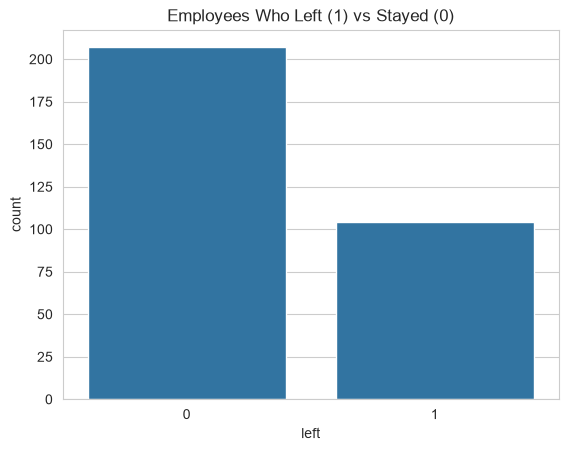

In [8]:
sns.countplot(x="left", data=df)
plt.title("Employees Who Left (1) vs Stayed (0)")
plt.show()

<!-- Observation: Out of 311 employees, 207 are still employed and 104 have left, an attrition rate of about 33%. -->

<!-- Insight: The data is moderately imbalanced (roughly 2 stayed for every 1 who left). Because of this, we use F1 score and class weights when building models, instead of relying on accuracy alone. -->

### 2. Attrition by department

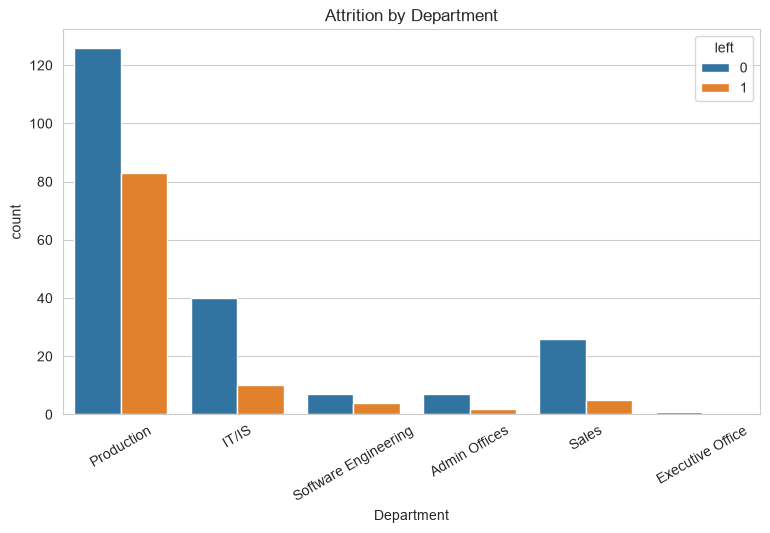

In [9]:
plt.figure(figsize=(9,5))
sns.countplot(x="Department", hue="left", data=df)
plt.xticks(rotation=30)
plt.title("Attrition by Department")
plt.show()

 <!-- Observation: Production is by far the largest department (about 209 employees) and has the most leavers (about 83 of the 104 total). Its attrition rate is roughly 40%. IT/IS lost about 10 of 50 employees (20%), Sales about 5 of 31 (16%), Admin Offices about 2 of 9 (22%), and Software Engineering about 4 of 11 (36%). The Executive Office has a single employee, who stayed. -->

 <!-- Insight: Production accounts for about 80% of all attrition, and its rate (~40%) is well above the company average of 33%. Sales and IT/IS keep their people much better. Software Engineering also shows a high rate, but with only 11 employees, one or two exits change the percentage a lot, so it should not be over-interpreted. -->

 <!-- Recommendation: Focus retention efforts on Production first, for example by reviewing workload, pay, and management practices there. Department is likely to be an important feature for the prediction model. -->

### 3. Why people left (only among those who left)

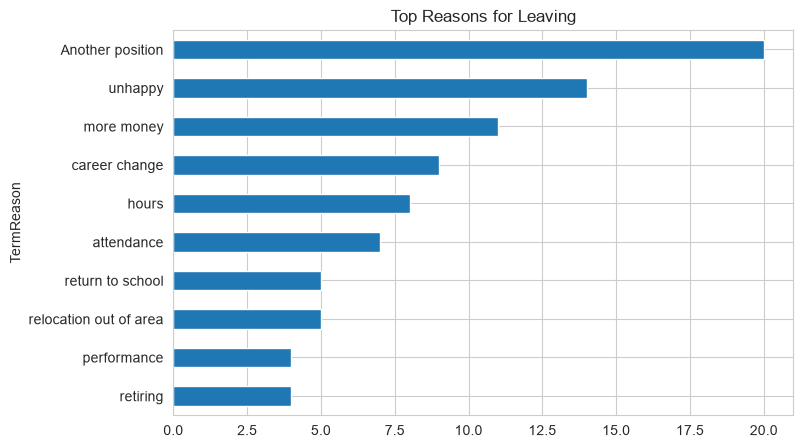

In [10]:
reasons = df[df["left"] == 1]["TermReason"].value_counts().head(10)
reasons.plot(kind="barh", figsize=(8,5))
plt.gca().invert_yaxis()
plt.title("Top Reasons for Leaving")
plt.show()

 <!-- Observation: Among the 104 employees who left, the most common reason was taking "another position" (20 people, about 19%), followed by "unhappy" (14), "more money" (11), "career change" (9), "hours" (8) and "attendance" (7). Return to school, relocation out of area, performance and retiring each account for 4 to 5 people. The chart shows only the top 10 reasons, which together cover about 87 of the 104 leavers. -->

<!-- Insight: Most exits are linked to factors the company can influence. "Another position", "unhappy", "more money", "career change" and "hours" together make up about 62 leavers (roughly 60%), which points to career growth, pay, job satisfaction and workload. Reasons the company can do little about, such as relocation, return to school and retiring, are a small share. Attendance and performance appear as reasons too, but those are cases where the company ended the employment, not the employee's choice. -->

 <!-- Recommendation: Offer clearer career paths and internal promotion opportunities, review pay against market rates, and run regular satisfaction check-ins to catch unhappy employees early. Also review working hours and scheduling, especially in Production, where most attrition happens. -->

### 4. Engagement, satisfaction, salary, absences vs leaving

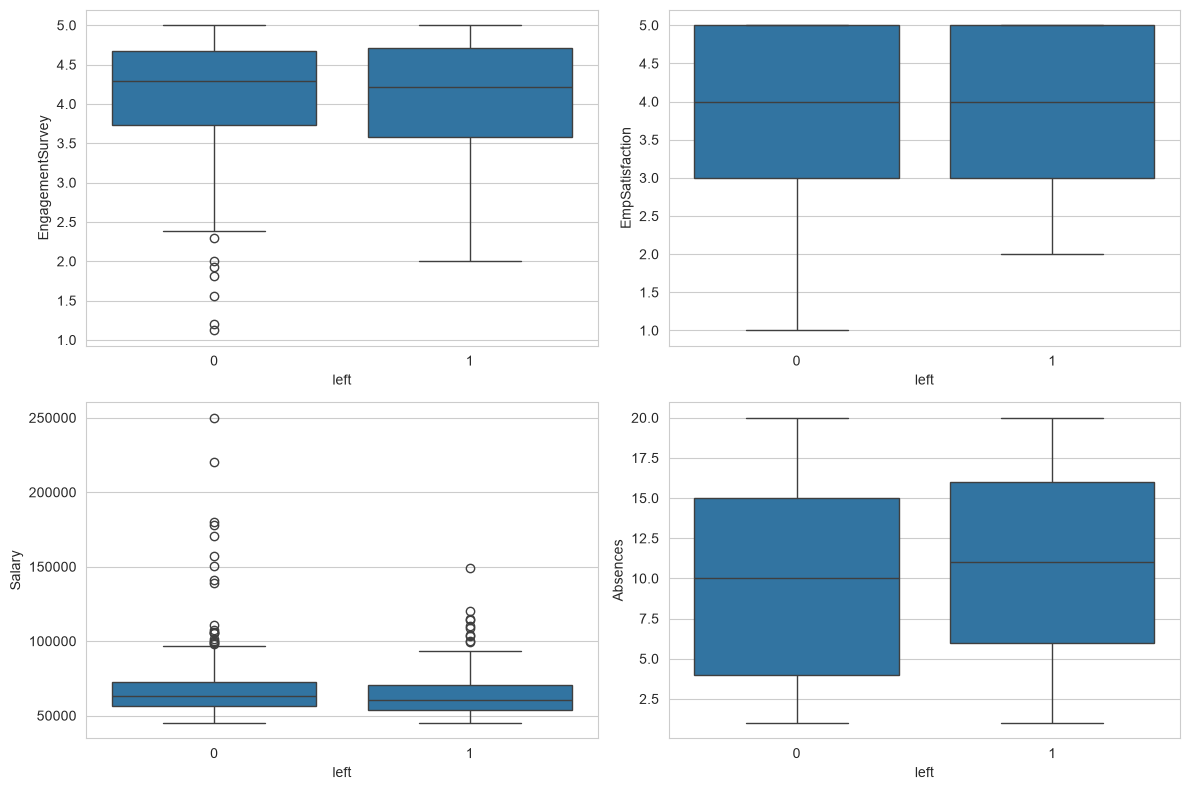

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12,8))
sns.boxplot(x="left", y="EngagementSurvey", data=df, ax=axes[0,0])
sns.boxplot(x="left", y="EmpSatisfaction", data=df, ax=axes[0,1])
sns.boxplot(x="left", y="Salary", data=df, ax=axes[1,0])
sns.boxplot(x="left", y="Absences", data=df, ax=axes[1,1])
plt.tight_layout()
plt.show()

 <!-- Observation: -->
<!-- - Engagement survey:** The medians are almost the same for both groups (about 4.3 for those who stayed, 4.2 for those who left). Employees who stayed have a few low outliers (scores of 1 to 2.3), while leavers have a slightly wider spread. -->
<!-- - Employee satisfaction: The two boxes look nearly identical, with a median of 4 and a range of 3 to 5 in both groups. -->
<!-- - Salary: Both groups have a median of roughly 60,000 to 65,000. Leavers sit slightly lower (median about 60,000 vs 63,000), and the stayers have more very high earners (outliers up to 250,000). -->
<!-- - Absences:** Leavers have a slightly higher median (about 11 vs 10) and a higher middle range (about 6 to 16 vs 4 to 15). -->

<!-- Insight: None of these four factors separates leavers from stayers clearly. The distributions overlap heavily, so an employee's engagement score, satisfaction rating or number of absences alone does not reveal who is likely to leave. The only hints are that leavers earn slightly less and are absent slightly more often. The very highest salaries (above about 150,000) belong almost entirely to employees who stayed, which suggests top earners are rarely lost. -->

<!-- Implication for modeling: Because these numeric features are weak predictors on their own, we should expect only moderate model accuracy (roughly 65 to 75%). Categorical features such as department, manager and recruitment source may carry more of the signal. -->

### 5. Attrition rate by recruitment source and by manager

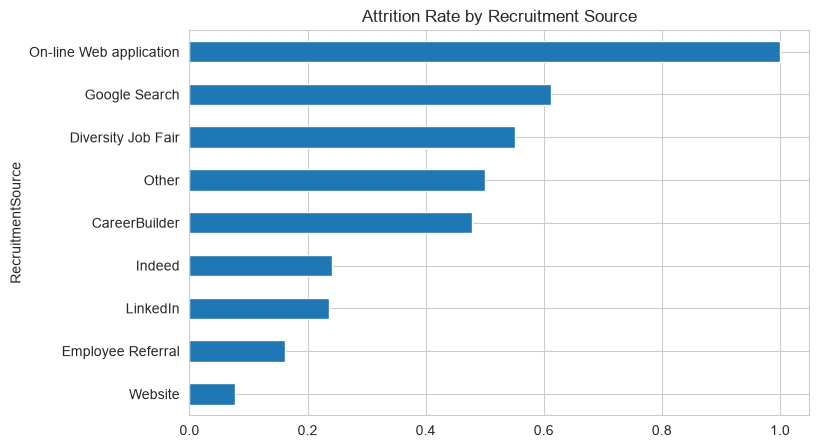

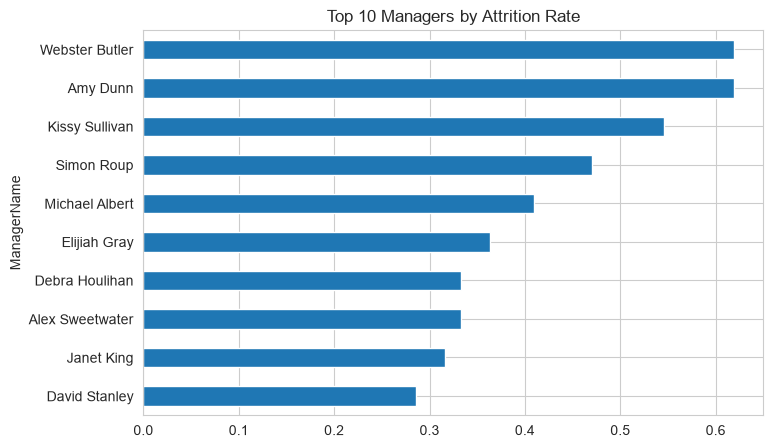

In [12]:
rate_source = df.groupby("RecruitmentSource")["left"].mean().sort_values()
rate_source.plot(kind="barh", figsize=(8,5), title="Attrition Rate by Recruitment Source")
plt.show()

rate_mgr = df.groupby("ManagerName")["left"].mean().sort_values(ascending=False).head(10)
rate_mgr.plot(kind="barh", figsize=(8,5), title="Top 10 Managers by Attrition Rate")
plt.gca().invert_yaxis()
plt.show()

 <!-- Observation (recruitment source): -->

| Source | Employees | Left | Attrition rate |
|---|---|---|---|
| Google Search | 49 | 30 | 61.2% |
| Diversity Job Fair | 29 | 16 | 55.2% |
| CareerBuilder | 23 | 11 | 47.8% |
| Indeed | 87 | 21 | 24.1% |
| LinkedIn | 76 | 18 | 23.7% |
| Employee Referral | 31 | 5 | 16.1% |
| Website | 13 | 1 | 7.7% |
| Other | 2 | 1 | 50.0% |
| On-line Web application | 1 | 1 | 100% |

<!-- "Other" and "On-line Web application" have only 2 and 1 employees, so they are excluded from the conclusions below. -->

Observation (manager): Webster Butler and Amy Dunn each lost 13 of 21 employees (61.9%), Kissy Sullivan lost 12 of 22 (54.5%), Simon Roup 8 of 17 (47.1%), and Michael Albert 9 of 22 (40.9%). Debra Houlihan (3 employees) and Alex Sweetwater (9 employees) have very small teams, so their rates are unreliable.

<!-- Insight: Google Search alone accounts for 30 of the 104 leavers (about 29%), and its attrition rate is nearly double the company average of 33%. Google Search, Diversity Job Fair and CareerBuilder all lose roughly half or more of their hires. Indeed and LinkedIn, the two largest channels after Google Search, perform better at about 24%. Employee Referral keeps 84% of its hires, which suggests referred employees fit better and stay longer. Website hires have the lowest attrition (1 of 13), though that group is small. Three managers (Butler, Dunn and Sullivan) account for 38 of the 104 leavers (about 37%), even though they manage only about 20% of the workforce (64 employees). -->

<!-- Caution: These patterns show association, not proof of cause. The high-attrition managers and channels may also be tied to particular departments or roles, such as Production, so the effects can overlap. -->

<!-- Recommendation: Reduce reliance on Google Search and review how those candidates are screened. Expand the employee referral program. Investigate the teams of the three highest-attrition managers through exit feedback and manager support or training. -->

<!-- Implication for modeling: RecruitmentSource and ManagerName show much larger differences between groups than engagement, satisfaction or absences, so they are likely to be among the most useful features. -->

In [14]:
src = df.groupby("RecruitmentSource")["left"].agg(["count", "sum", "mean"])
src.columns = ["employees", "left", "rate"]
print(src.sort_values("rate", ascending=False))

mgr = df.groupby("ManagerName")["left"].agg(["count", "sum", "mean"])
mgr.columns = ["employees", "left", "rate"]
print(mgr.sort_values("rate", ascending=False).head(10))

                         employees  left      rate
RecruitmentSource                                 
On-line Web application          1     1  1.000000
Google Search                   49    30  0.612245
Diversity Job Fair              29    16  0.551724
Other                            2     1  0.500000
CareerBuilder                   23    11  0.478261
Indeed                          87    21  0.241379
LinkedIn                        76    18  0.236842
Employee Referral               31     5  0.161290
Website                         13     1  0.076923
                 employees  left      rate
ManagerName                               
Webster Butler          21    13  0.619048
Amy Dunn                21    13  0.619048
Kissy Sullivan          22    12  0.545455
Simon Roup              17     8  0.470588
Michael Albert          22     9  0.409091
Elijiah Gray            22     8  0.363636
Debra Houlihan           3     1  0.333333
Alex Sweetwater          9     3  0.333333
Janet Kin

### 6. Correlation heatmap of the numeric columns we will use

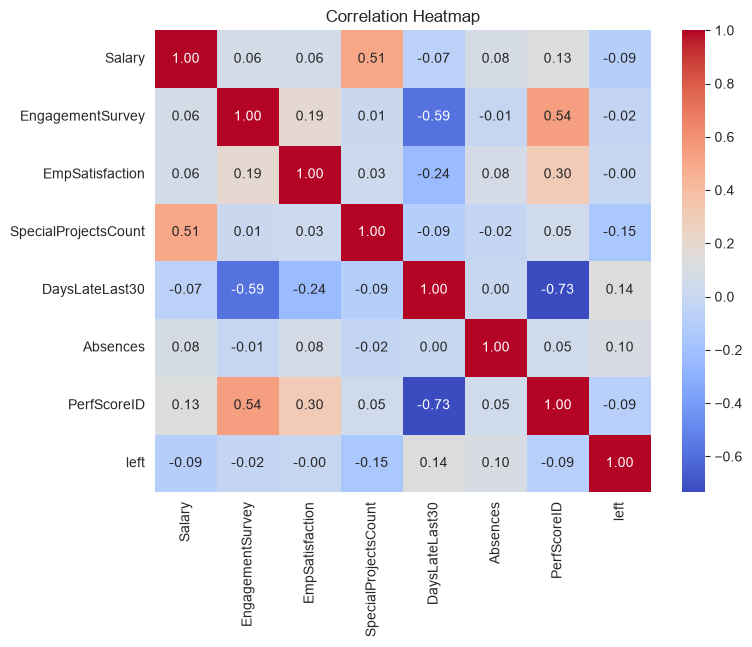

In [13]:
num_cols_all = ["Salary", "EngagementSurvey", "EmpSatisfaction", "SpecialProjectsCount",
                "DaysLateLast30", "Absences", "PerfScoreID", "left"]
plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols_all].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

<!-- Observation (correlation with leaving): No feature has a strong linear relationship with `left`. The strongest are SpecialProjectsCount (-0.15), DaysLateLast30 (0.14), Absences (0.10), Salary (-0.09) and PerfScoreID (-0.09). Engagement survey (-0.02) and employee satisfaction (0.00) are essentially unrelated to leaving. -->

<!-- Observation (relationships between features): -->
- DaysLateLast30 and PerfScoreID are strongly negatively correlated (-0.73): employees who are late more often have lower performance scores.
- DaysLateLast30 and EngagementSurvey are also negatively correlated (-0.59): late employees tend to be less engaged.
- EngagementSurvey and PerfScoreID are positively correlated (0.54), and Salary and SpecialProjectsCount are positively correlated (0.51).

<!-- Insight: Leaving is not explained by any single numeric factor. The direction of the weak signals still makes sense: leavers tend to take on fewer special projects, arrive late more often, have more absences and earn slightly less. This matches the boxplots, where the groups overlapped heavily. The strong links between lateness, engagement and performance show that these variables describe the same underlying behavior ("disengaged employees"), so they carry overlapping information. -->

<!-- Implication for modeling: Because the linear correlations with `left` are all below 0.15, the numeric features alone will give only modest predictive power. Categorical features such as department, manager and recruitment source (which showed large differences in charts 2 and 5) should contribute most. We use tree-based models (Decision Tree, Random Forest) alongside Logistic Regression because they can capture non-linear patterns and interactions that a correlation heatmap cannot show. `PerfScoreID` is dropped from the model because `PerformanceScore` already contains the same information. -->

## Choose Features and Split the Data

In [16]:
num_features = ["Salary", "EngagementSurvey", "EmpSatisfaction",
                "SpecialProjectsCount", "DaysLateLast30", "Absences"]
cat_features = ["Department", "RecruitmentSource", "ManagerName", "PerformanceScore"]

X = df[num_features + cat_features]
y = df["left"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(248, 10) (63, 10)


## Train and compare the Models

In [17]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8,
                                            class_weight="balanced", random_state=42),
    "SVM": SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42),
}

pipes, results = {}, []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", clf)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, X, y, cv=5, scoring="f1").mean()
    pipes[name] = pipe
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "CV F1 (5-fold)": cv,
    })

results_df = pd.DataFrame(results).sort_values("CV F1 (5-fold)", ascending=False)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,CV F1 (5-fold)
3,SVM,0.698413,0.538462,0.666667,0.595745,0.571685
0,Logistic Regression,0.634921,0.466667,0.666667,0.549020,0.568301
2,Random Forest,0.698413,0.541667,0.619048,0.577778,0.528195
1,Decision Tree,0.634921,0.444444,0.380952,0.410256,0.399391


 <!-- Model Comparison -->

Four models were trained on 248 employees (80%) and tested on 63 employees (20%): Logistic Regression, Decision Tree, Random Forest and SVM. All used class weights to handle the imbalance (33% leavers). Performance was also checked with 5-fold cross-validation, since the dataset is small.

| Model | Accuracy | Precision | Recall | F1 | CV F1 (5-fold) |
|---|---|---|---|---|---|
| SVM | 0.698 | 0.538 | 0.667 | 0.596 | 0.572 |
| Logistic Regression | 0.635 | 0.467 | 0.667 | 0.549 | 0.568 |
| Random Forest | 0.698 | 0.542 | 0.619 | 0.578 | 0.528 |
| Decision Tree | 0.635 | 0.444 | 0.381 | 0.410 | 0.399 |

<!-- Observation: SVM achieved the best cross-validated F1 score (0.572) and a test accuracy of about 70%, with Logistic Regression a very close second (0.568). Random Forest matched SVM's test accuracy but scored lower in cross-validation, indicating less stable performance. The Decision Tree performed worst, identifying only 38% of the employees who actually left. -->

<!-- Insight: Overall performance is moderate, which is expected given the small dataset (311 employees) and the weak relationship between individual numeric factors and attrition seen in the EDA. Recall (about 0.67 for SVM) is the most useful metric here, because the goal is to catch employees at risk of leaving. Precision is lower (about 0.54), meaning roughly half of the employees flagged as likely to leave will actually leave. -->

<!-- Conclusion: SVM is selected as the final model. It can be used as an early-warning tool to prioritize retention conversations, not as an automatic decision-maker. -->

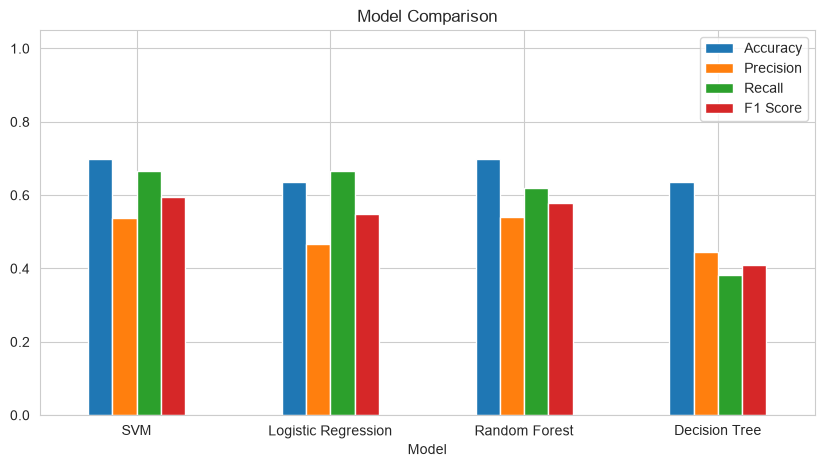

In [18]:
results_df.set_index("Model")[["Accuracy","Precision","Recall","F1 Score"]].plot(
    kind="bar", figsize=(10,5))
plt.title("Model Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()

<!-- Observation: SVM and Random Forest have the highest accuracy (about 0.70). SVM and Logistic Regression have the highest recall (about 0.67), meaning they catch two out of three employees who actually left. Precision is the lowest metric for every model (0.44 to 0.54). Decision Tree is lowest on almost every metric, and its recall (0.38) is clearly below the others. -->

<!-- Insight: SVM gives the most balanced result, with the best F1 score and a good recall. Precision below 0.55 means that roughly half of the employees flagged as "likely to leave" will actually stay, so the model works best as an early-warning screen for HR to follow up on, not as a final verdict on any individual. The single Decision Tree is too simple for this data, while the models that combine many features (SVM, Random Forest, Logistic Regression) perform better. -->

## Evaluate the Best Model 

Best model: SVM
              precision    recall  f1-score   support

      Stayed       0.81      0.71      0.76        42
        Left       0.54      0.67      0.60        21

    accuracy                           0.70        63
   macro avg       0.67      0.69      0.68        63
weighted avg       0.72      0.70      0.70        63



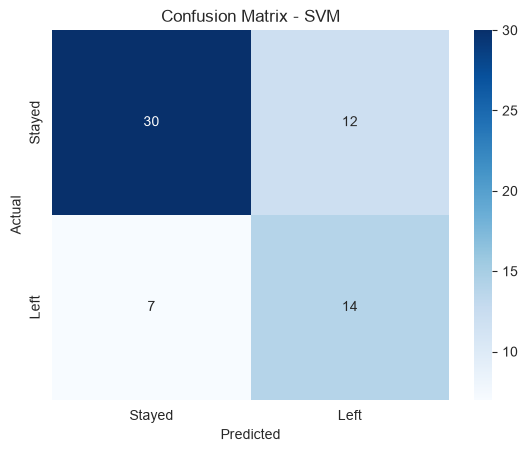

In [19]:
best_name = results_df.iloc[0]["Model"]
best_model = pipes[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Stayed","Left"]))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed","Left"], yticklabels=["Stayed","Left"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

 <!-- Evaluation of the Best Model (SVM) -->

<!-- Confusion matrix (63 test employees): -->

| | Predicted Stayed | Predicted Left |
|---|---|---|
| Actually Stayed (42) | 30 correct | 12 false alarms |
| Actually Left (21) | 7 missed | 14 correctly caught |

<!-- Observation: -->
- The model correctly identified 14 of the 21 employees who left (recall 0.67) and 30 of the 42 who stayed (recall 0.71). Overall accuracy is 70%.
- It missed 7 leavers (false negatives) and wrongly flagged 12 stayers as likely to leave (false positives).
- For the "Left" class, precision is 0.54: of the 26 employees flagged as likely to leave, 14 actually left. For the "Stayed" class, precision is 0.81: when the model predicts someone will stay, it is right 81% of the time.
- The F1 score for "Left" is 0.60, compared with 0.76 for "Stayed", so the model is better at spotting stayers than leavers.

<!-- Insight: The model catches about two out of three at-risk employees, which makes it useful as a screening tool. The cost is a fairly high false alarm rate (12 of 42 stayers were flagged). In an HR setting, a false alarm usually just means an extra check-in conversation, while a missed leaver means losing someone without warning. That is why we used class weights and favored recall over precision when choosing the model. -->

<!-- Limitation: The test set has only 63 employees (21 leavers), so each single prediction shifts the scores by several percentage points. These results should be treated as indicative, not exact. A larger dataset would give more reliable estimates. -->

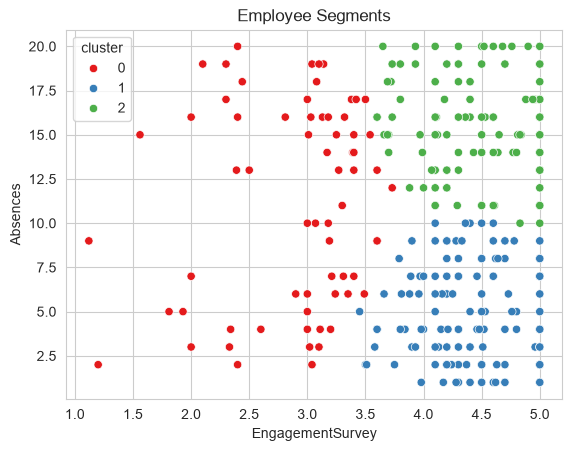

In [22]:
from sklearn.cluster import KMeans
cols = ["EngagementSurvey", "Absences"]
km = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = km.fit_predict(StandardScaler().fit_transform(df[cols]))
sns.scatterplot(x="EngagementSurvey", y="Absences", hue="cluster", data=df, palette="Set1")
plt.title("Employee Segments")
plt.show()

In [24]:
cluster_summary = df.groupby("cluster").agg(
    employees=("left", "count"),
    left=("left", "sum"),
    attrition_rate=("left", "mean"),
    avg_engagement=("EngagementSurvey", "mean"),
    avg_absences=("Absences", "mean"),
    avg_salary=("Salary", "mean"),
).round(2)
cluster_summary

,employees,left,attrition_rate,avg_engagement,avg_absences,avg_salary
cluster,,,,,,
0,67,25,0.37,2.90,11.10,66240.79
1,125,36,0.29,4.40,4.93,69193.98
2,119,43,0.36,4.49,15.33,70403.80


 <!-- Employee Segmentation (K-Means) -->

K-Means with 3 clusters was applied to engagement score and absences (both standardized) to group employees by behavior.

| Cluster | Description | Employees | Left | Attrition rate | Avg engagement | Avg absences | Avg salary |
|---|---|---|---|---|---|---|---|
| 0 | Low engagement | 67 | 25 | 37% | 2.90 | 11.1 | 66,241 |
| 1 | Engaged, regular attendance | 125 | 36 | 29% | 4.40 | 4.9 | 69,194 |
| 2 | Engaged, frequently absent | 119 | 43 | 36% | 4.49 | 15.3 | 70,404 |

<!-- Observation: The largest group (Cluster 1, 125 employees) is highly engaged with few absences and has the lowest attrition at 29%. Cluster 0 (low engagement, average about 2.9) loses 37% of its people, and Cluster 2 (high engagement but about 15 absences on average) loses 36%. The company average is 33%. -->

<!-- Insight: Both warning signs, low engagement and high absences, are linked to higher attrition than the healthy segment, by about 7 to 8 percentage points. Cluster 2 is notable: its employees report high engagement, yet they are absent often and leave at nearly the same rate as the disengaged group. This suggests absences can be an early warning even when survey scores look fine. Cluster 2 also contains the most leavers in absolute terms (43 of 104). -->

<!-- Caution: The differences between segments are modest (29% vs 36-37%), so these groups separate attrition only weakly. This matches the EDA and the model results, where no single behavior strongly predicts leaving. K-Means is unsupervised and does not use the `left` column. The attrition rates were checked afterwards, so this is a supporting analysis and not part of the prediction model. -->

<!-- Recommendation: Prioritize check-ins with low-engagement employees (Cluster 0) and look into the causes of high absences in Cluster 2, such as workload, scheduling or health, before they turn into resignations. -->

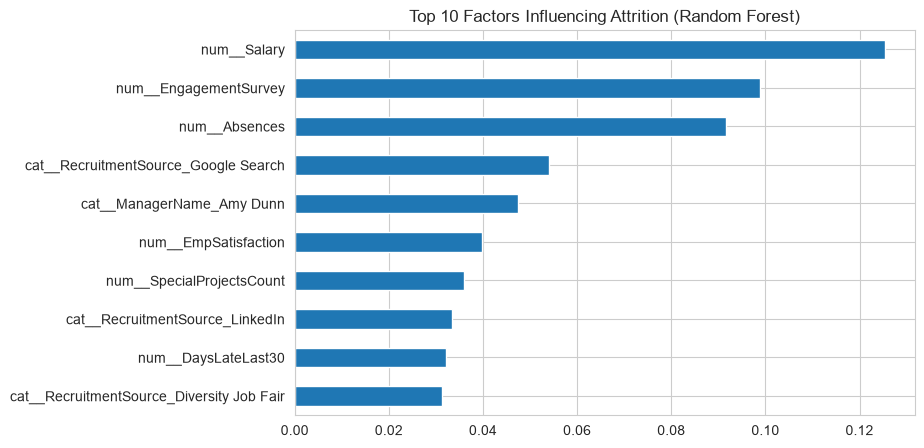

In [23]:
rf = pipes["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names)
imp.sort_values(ascending=False).head(10).plot(kind="barh", figsize=(8,5))
plt.gca().invert_yaxis()
plt.title("Top 10 Factors Influencing Attrition (Random Forest)")
plt.show()

  <!-- Key Factors Influencing Attrition (Random Forest) --> -->

<!-- Observation: The top three factors are all numeric: Salary (importance about 0.125), Engagement Survey score (about 0.099) and Absences (about 0.092). Next come two categories: hired through Google Search (about 0.054) and managed by Amy Dunn (about 0.047). Employee satisfaction, special projects count, hired through LinkedIn, days late in the last 30 days and hired through the Diversity Job Fair each add about 0.03 to 0.04. -->

<!-- Insight: -->
- Pay, engagement and attendance are the strongest signals. Together they account for roughly 30% of the model's total importance. The EDA showed these have only weak individual relationships with leaving, so the model is likely using combinations (for example, a mid-level salary together with low engagement and high absences) rather than any single value.
- Hiring channel matters. Google Search and Diversity Job Fair hires, which had attrition of 61% and 55% in the EDA, both appear in the top 10. LinkedIn also appears, as a channel with lower attrition.
- Manager matters. Amy Dunn's team (62% attrition) is the only individual manager in the top 10.
- Department is not in the top 10, even though Production has the most leavers. Its effect is mostly captured by the other features, and the department categories are small groups.

<!-- Caution: Feature importance shows what the model relies on to predict, not what causes people to leave. Salary is the top feature partly because it is a continuous number that offers many split points for the trees, which tends to inflate the importance of continuous features. Importance values are also spread out, since no single feature dominates (the highest is only about 0.125). This is consistent with the moderate accuracy of about 70%. These results come from the Random Forest, while the final deployed model is SVM, which cannot report importance directly. -->

<!-- Recommendation: Review pay for employees at risk, monitor engagement scores and rising absences as early-warning signs, and review recruitment through Google Search and the management practices on the highest-attrition teams. -->

## Save the Best Model

In [25]:
options = {
    "departments": sorted(df["Department"].unique().tolist()),
    "sources": sorted(df["RecruitmentSource"].unique().tolist()),
    "managers": sorted(df["ManagerName"].unique().tolist()),
    "perf_scores": sorted(df["PerformanceScore"].unique().tolist()),
    "salary_min": int(df["Salary"].min()),
    "salary_max": int(df["Salary"].max()),
}

joblib.dump(best_model, "model.pkl")
joblib.dump(options, "options.pkl")

import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [26]:
loaded = joblib.load("model.pkl")
print(loaded.predict(X_test.head(3)), loaded.predict_proba(X_test.head(3)))
import os
print(os.listdir("."))

[1 0 0] [[0.47813666 0.52186334]
 [0.69748286 0.30251714]
 [0.81968183 0.18031817]]
['hr_cleaned_data.json', 'K-Means.ipynb', 'Data Analysis.ipynb', 'Feature Engineering.ipynb', 'salary_bonus.png', 'Untitled1.ipynb', 'Machine Learning.ipynb', 'PYTHON', 'Data_Cleaning.ipynb', 'Conditional.k_Filteringk.ipynb', 'Untitled.ipynb', 'Visualization.ipynb', 'Dataset', 'Pandask.ipynb', 'Pizza Sales.ipynb', 'Numpyk.ipynb', 'Linear Regression.ipynb', 'SQL.ipynb', 'model.pkl', 'pca.png', 'hr_attrition_project', 'Financial Analysis.ipynb', 'options.pkl', '.ipynb_checkpoints', 'Eg Data Cleaning.ipynb', 'logistics Regression.ipynb', 'hr_cleaned_data.csv', 'hr_cleaned_data.xlsx', 'SVM.ipynb', 'Decision Tree and Random Forest.ipynb', 'Prompt Engineering.ipynb']


In [27]:
import shutil, os
shutil.move("model.pkl", "hr_attrition_project/model.pkl")
shutil.move("options.pkl", "hr_attrition_project/options.pkl")
print(os.listdir("hr_attrition_project"))

['HR_Attrition_Analysis.ipynb', 'model.pkl', 'options.pkl', '.ipynb_checkpoints', 'hr_cleaned_data.csv']


In [28]:
import os
print(os.path.abspath("hr_attrition_project"))

/Users/kalyanthapa/kalyan broadinfosys class/hr_attrition_project
